In [1]:
import numpy as np
import time
import torch
import matplotlib.pyplot as plt
plt.rc('text', usetex=False)
import multiprocessing as mp
from typing import Union


from abc import ABC
from epde.preprocessing.cheb import process_point_cheb

from epde.preprocessing.deriv_calculators import Heatmap, AbstractDeriv, AdaptiveFiniteDeriv, PolynomialDeriv, SpectralDeriv, TotalVariation




In [2]:
def masked_mse(arr1, arr2, inner_start=5, inner_end=27):
    """
    Вычисляет MSE между двумя массивами, игнорируя внутреннюю часть [inner_start:inner_end, inner_start:inner_end].
    
    Параметры:
    ----------
    arr1, arr2 : numpy.ndarray
        Двумерные массивы одинакового размера.
    inner_start, inner_end : int
        Границы внутренней области, которую нужно исключить из расчёта.
        
    Возвращает:
    -----------
    mse : float
        Среднеквадратичная ошибка (без учета внутренней части).
    """
    # Создаём маску: True там, где элементы ДОЛЖНЫ учитываться в MSE (вне внутренней части)
    mask = np.ones_like(arr1, dtype=bool)
    mask[inner_start:inner_end, inner_start:inner_end] = False
    
    # Применяем маску к обоим массивам
    masked_arr1 = arr1[mask]
    masked_arr2 = arr2[mask]
    
    # Вычисляем MSE только по валидным элементам
    squared_errors = (masked_arr1 - masked_arr2) ** 2
    mse = np.mean(squared_errors)
    
    return mse

Mean Squared Error (MSE) for noise level 0:
  u_xx: 0.4112506272057373
  u_x: 0.00465825246055898
  u_t: 0.0009560127789643596
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 0.4424924745538448
  u_x: 0.00464039766209295
  u_t: 0.008205458522489759
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 0.5433505909847938
  u_x: 0.004794923306941676
  u_t: 0.02410421810240906


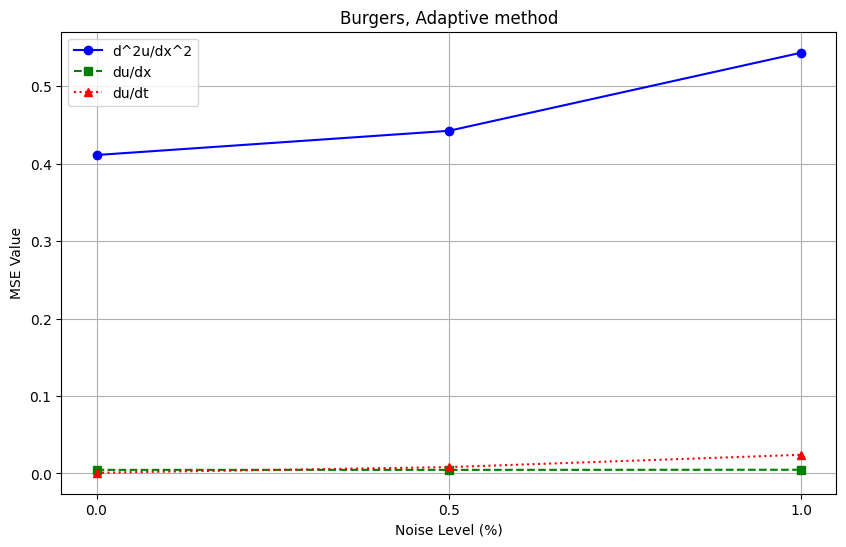

In [3]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)


noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xx = np.load(f'Burgers_Gradient_xx_noise{noise}.npy')
    u_x = np.load(f'Burgers_Gradient_x_noise{noise}.npy')
    u_t = np.load(f'Burgers_Gradient_t_noise{noise}.npy')
    

    gradient_xx = np.load(f'Burgers_Adaptive_xx_noise{noise}.npy')
    gradient_x = np.load(f'Burgers_Adaptive_x_noise{noise}.npy')
    gradient_t = np.load(f'Burgers_Adaptive_t_noise{noise}.npy')

    # Вычисление MSE для каждого случая
    mse_u_xx = masked_mse(u_xx, gradient_xx, inner_start=5, inner_end=27)
    mse_u_x = masked_mse(u_x, gradient_x, inner_start=5, inner_end=27)
    mse_u_t = masked_mse(u_t, gradient_t, inner_start=5, inner_end=27)

    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('Burgers, Adaptive method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Burgers_Adaptive_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 0.9714241327861276
  u_x: 0.0638574707911083
  u_t: 0.0014141519590203126
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 2.1655473956255995
  u_x: 0.06510379693450061
  u_t: 0.025911850010849953
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 5.2326163308651905
  u_x: 0.06602273835837676
  u_t: 0.07402241883954319


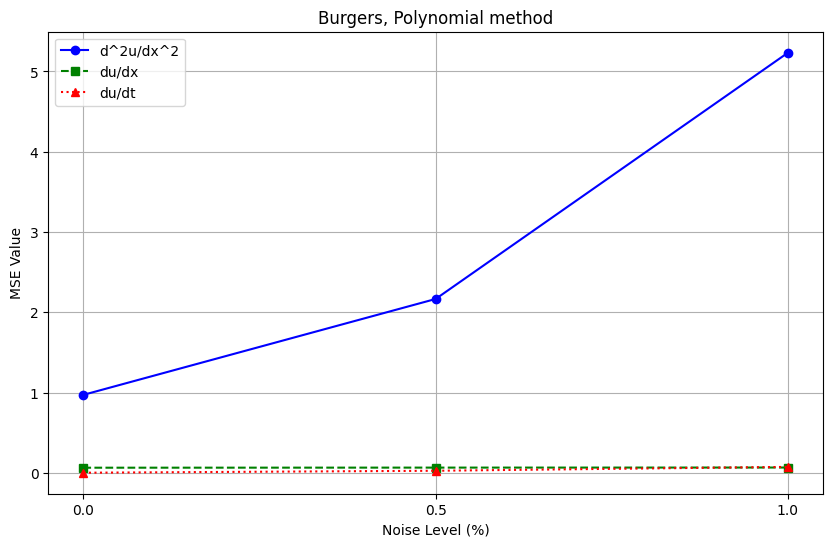

In [ ]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xx = np.load(f'Burgers_Gradient_xx_noise{noise}.npy')
    u_x = np.load(f'Burgers_Gradient_x_noise{noise}.npy')
    u_t = np.load(f'Burgers_Gradient_t_noise{noise}.npy')
    
    gradient_xx = np.load(f'Burgers_Polynomial_xx_noise{noise}.npy')
    gradient_x = np.load(f'Burgers_Polynomial_x_noise{noise}.npy')
    gradient_t = np.load(f'Burgers_Polynomial_t_noise{noise}.npy')


    # Вычисление MSE для каждого случая
    mse_u_xx = masked_mse(u_xx, gradient_xx, inner_start=5, inner_end=27)
    mse_u_x = masked_mse(u_x, gradient_x, inner_start=5, inner_end=27)
    mse_u_t = masked_mse(u_t, gradient_t, inner_start=5, inner_end=27)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('Burgers, Polynomial method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Burgers_Polynomial_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 20.939993310242553
  u_x: 0.12961670168748415
  u_t: 13.19794382550922
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 21.067271944547503
  u_x: 0.12988947709745846
  u_t: 13.12570339040148
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 21.430892609010225
  u_x: 0.13105129751145622
  u_t: 13.261098954844645


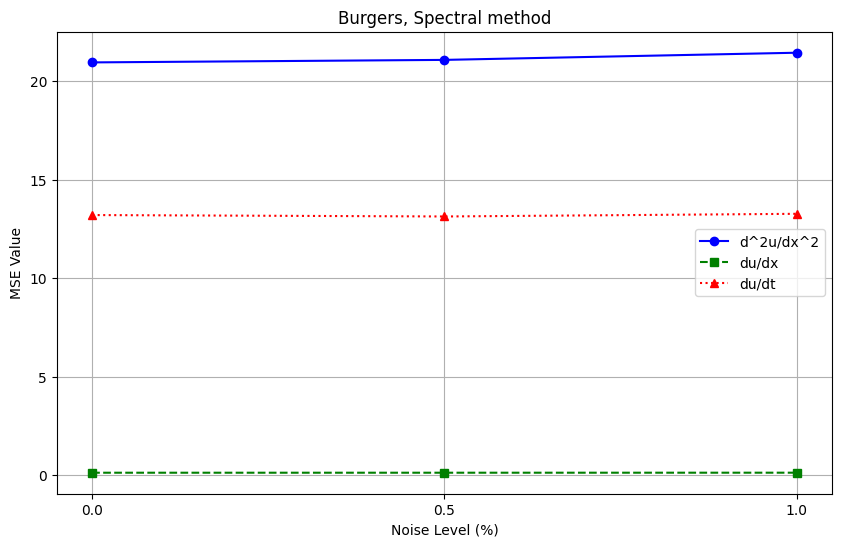

In [ ]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xx = np.load(f'Burgers_Gradient_xx_noise{noise}.npy')
    u_x = np.load(f'Burgers_Gradient_x_noise{noise}.npy')
    u_t = np.load(f'Burgers_Gradient_t_noise{noise}.npy')
    
    gradient_xx = np.load(f'Burgers_Spectral_xx_noise{noise}.npy')
    gradient_x = np.load(f'Burgers_Spectral_x_noise{noise}.npy')
    gradient_t = np.load(f'Burgers_Spectral_t_noise{noise}.npy')
    

    # Вычисление MSE для каждого случая
    mse_u_xx = masked_mse(u_xx, gradient_xx, inner_start=5, inner_end=27)
    mse_u_x = masked_mse(u_x, gradient_x, inner_start=5, inner_end=27)
    mse_u_t = masked_mse(u_t, gradient_t, inner_start=5, inner_end=27)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('Burgers, Spectral method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Burgers_Spectral_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 105.02955356714145
  u_x: 3.909099825452205
  u_t: 0.6640709133909316
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 105.46078733530372
  u_x: 3.9047899106329447
  u_t: 0.7112436591819093
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 106.28097425292694
  u_x: 3.9179040225072574
  u_t: 0.8142864589587027


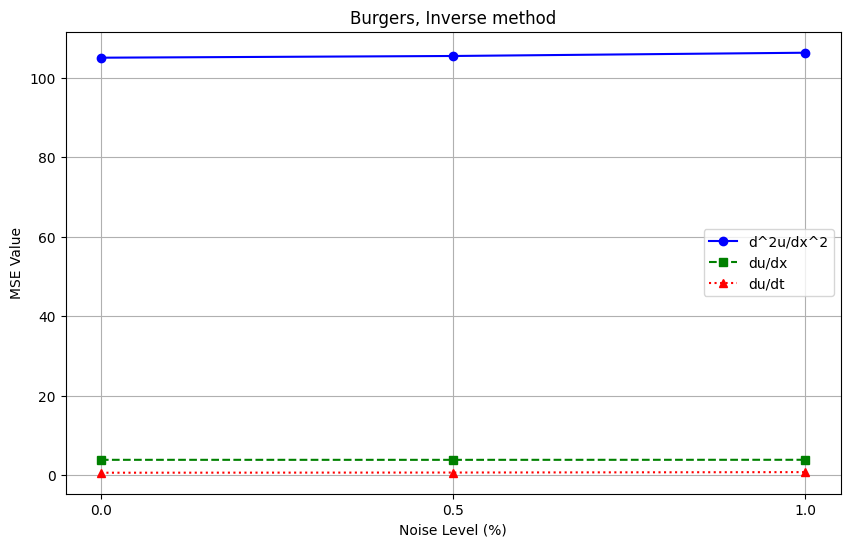

In [ ]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xx = np.load(f'Burgers_Gradient_xx_noise{noise}.npy')
    u_x = np.load(f'Burgers_Gradient_x_noise{noise}.npy')
    u_t = np.load(f'Burgers_Gradient_t_noise{noise}.npy')
    
    gradient_xx = np.load(f'Burgers_Inverse_xx_noise{noise}.npy')
    gradient_x = np.load(f'Burgers_Inverse_x_noise{noise}.npy')
    gradient_t = np.load(f'Burgers_Inverse_t_noise{noise}.npy')

     
    # Вычисление MSE для каждого случая
    mse_u_xx = masked_mse(u_xx, gradient_xx, inner_start=5, inner_end=27)
    mse_u_x = masked_mse(u_x, gradient_x, inner_start=5, inner_end=27)
    mse_u_t = masked_mse(u_t, gradient_t, inner_start=5, inner_end=27)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('Burgers, Inverse method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Burgers_Inverse_error.pdf', format='pdf')
plt.show()


Mean Squared Error (MSE) for noise level 0:
  u_xx: 106.54665049748048
  u_x: 4.498321429633976
  u_t: 0.5659334428124151
Mean Squared Error (MSE) for noise level 0.005:
  u_xx: 106.95644033504429
  u_x: 4.493766525723713
  u_t: 0.6153198195997241
Mean Squared Error (MSE) for noise level 0.01:
  u_xx: 107.79623205745415
  u_x: 4.508398227536126
  u_t: 0.7133665801658834


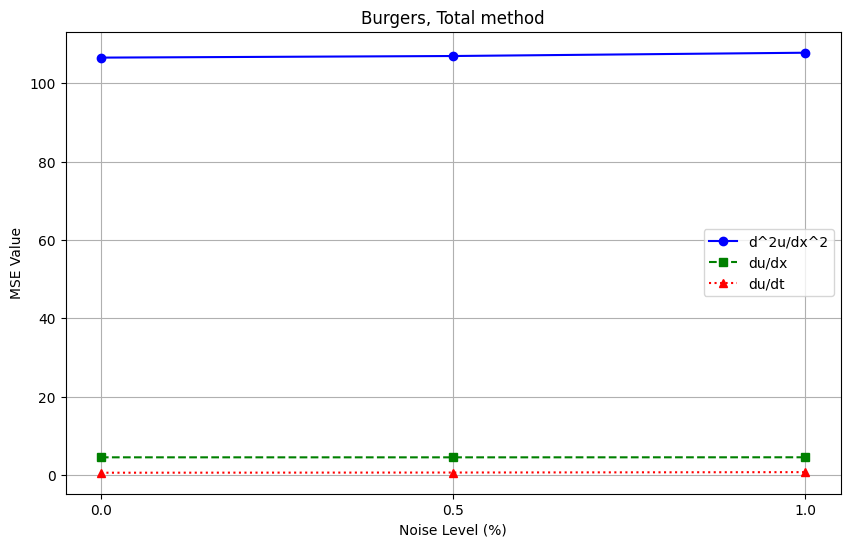

In [ ]:
#ошибка дифференцирования между аналитической производной и численной для каждого слагаемого
import matplotlib as mpl
mpl.rc('text', usetex=False)
def calculate_mse(matrix1, matrix2):
    return np.mean((matrix1 - matrix2) ** 2)

noise_levels = [0, 0.005, 0.01]
noise_levels_percent = [0, 0.5, 1]

mse_values_u_xx = []
mse_values_u_x = []
mse_values_u_t = []

for noise in noise_levels:
    u_xx = np.load(f'Burgers_Gradient_xx_noise{noise}.npy')
    u_x = np.load(f'Burgers_Gradient_x_noise{noise}.npy')
    u_t = np.load(f'Burgers_Gradient_t_noise{noise}.npy')
    
    gradient_xx = np.load(f'Burgers_Total_xx_noise{noise}.npy')
    gradient_x = np.load(f'Burgers_Total_x_noise{noise}.npy')
    gradient_t = np.load(f'Burgers_Total_t_noise{noise}.npy')
 
        
    # Вычисление MSE для каждого случая
    mse_u_xx = masked_mse(u_xx, gradient_xx, inner_start=5, inner_end=27)
    mse_u_x = masked_mse(u_x, gradient_x, inner_start=5, inner_end=27)
    mse_u_t = masked_mse(u_t, gradient_t, inner_start=5, inner_end=27)
    
    mse_values_u_xx.append(mse_u_xx)
    mse_values_u_x.append(mse_u_x)
    mse_values_u_t.append(mse_u_t)
    
    print(f'Mean Squared Error (MSE) for noise level {noise}:')
    print(f'  u_xx: {mse_u_xx}')
    print(f'  u_x: {mse_u_x}')
    print(f'  u_t: {mse_u_t}')

plt.figure(figsize=(10, 6))
plt.plot(noise_levels_percent, mse_values_u_xx, marker='o', linestyle='-', color='b', label='d^2u/dx^2')
plt.plot(noise_levels_percent, mse_values_u_x, marker='s', linestyle='--', color='g', label='du/dx')
plt.plot(noise_levels_percent, mse_values_u_t, marker='^', linestyle=':', color='r', label='du/dt')

plt.title('Burgers, Total method')
plt.xlabel('Noise Level (%)')
plt.ylabel('MSE Value')
plt.xticks(noise_levels_percent)
plt.legend()
plt.grid()
plt.savefig('Burgers_Total_error.pdf', format='pdf')
plt.show()
